# Problem 3: Geometric Brownian Motion

We lat $X(t) = \sigma B(t), t>0$ where B(t) is standard Brownian motion with unit variance, $\sigma > 0$ is the scale parameter. $X(0) = B(0) = 0$. We let $\tau_{a,b} = min\{t \geq 0, X(t) \in \{-b, a\} \}$ be the first time a stock reaches the treshold a or -b. We are interested in the probability of the process reaching threshold −b given it starts at 0. The probability of reaching threshold a before b is given as: $P(X(\tau_{a,b}) = a \mid X(0) = 0) = \frac{b}{a+b}$. We also have $E[\tau_{a,b}] = \frac{ab}{\sigma^2}$.

We are now interested in the currency price $Y(t)= \{exp(\mu + \sigma B(t))\}$ $t \geq 0$ with $B(0) = 0$ and $\mu = log(50)$. We assume $\sigma^2 = 4$

In [41]:
# Required libaries

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

### Problem 3a) 

Per Ivar buys at 50 kr and sells if it hits 75 kr or 25 kr. We want to calculate the probability of Per Ivar gaining, that is the probability of the price hitting 75 kr before 25.

We start by considering what this means for $X(t)$:

$Y(t) = 75 \implies \mu + X(t) = log(75) \implies X(t) = log(1.5)$

$Y(t) = 25 \implies \mu + X(t) = log(25) \implies X(t) = log(0.5)$

$P(\text{price hits 75 before 25}) = P(X(\tau_{a,b}) = a \mid X(0) = 0) = \frac{b}{a+b}$

With $a = log(1.5)$ and $b = -log(0.5)$

$P(\text{price hits 75 before 25}) = \frac{-log(0.5)}{log(1.5)-log(0.5)} = 0.631$

### Problem 3b)

We want to calculate the expected amount of days before Per Ivar has to sell. We get

$E[\text{days to sell}] = \frac{ab}{\sigma^2} = \frac{-log(0.5) log(1.5)}{4} = 0.07 days = 1.7 hours$

We confirm our calculations by simulating in python.

In [2]:
def simulate_standard_bm(T, N, num_paths=1):

    dt = T / N
    t = np.linspace(0, T, N + 1)

    Z = np.random.standard_normal(size=(N, num_paths))

    dW = np.sqrt(dt) * Z

    dW = np.vstack([np.zeros((1, num_paths)), dW])

    # Cumulative sum yields W(t)
    W = np.cumsum(dW, axis=0)

    return t, W


def simulate_gbm(T, N, sigma, mu, num_paths = 1):


    t, W = simulate_standard_bm(T, N, num_paths = num_paths)

    Y = np.exp(mu + sigma * W)

    return t, Y


In [34]:
sigma = 2
mu = np.log(50)

t, Y = simulate_gbm(1, 100000, sigma, mu, num_paths = 100)

#Boolean mask to find where values are beyond the limits
mask = (Y <= 25) | (Y >= 75)

#Finding the first occurrence
first_indices = np.argmax(mask, axis=0)

#Finding the corresponding times
times = t[first_indices]

print(f"Expected time: {round(np.average(times), 3)}")

Expected time: 0.068


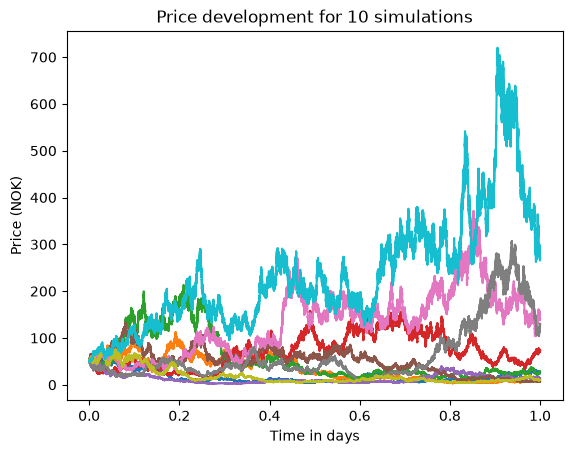

In [37]:
fig, ax = plt.subplots()

for i in range(10):
    ax.plot(t, Y[:, i])

ax.set(xlabel = "Time in days", ylabel = "Price (NOK)", title = "Price development for 10 simulations")

plt.show()

### Problem 3c)

We simulate the expected time in days that Per Ivar owned the cryptocurrency before
selling, conditional on the price reaching 75 kroner before 25 kroner both by simulation and numerical integration.

In [40]:
sigma = 2
mu = np.log(50)

t, Y = simulate_gbm(1, 100000, sigma, mu, num_paths = 1000)

#Boolean mask to find where values are beyond the limits
mask = (Y <= 25) | (Y >= 75)
#Finding the first occurrence
first_indices = np.argmax(mask, axis=0)
#Finding the corresponding times
times = t[first_indices]

#Finding the values at exit
path_indices = np.arange(Y.shape[1])
hit_values = Y[first_indices, path_indices]

#Finding the paths that hit 75 first
hit_upper_first = hit_values >= 75

#Extracting only the times for the paths hitting 75 first
exit_indexes_upper = first_indices[hit_upper_first]
exit_times_upper = t[exit_indexes_upper]

print(f"Expected time conditional on reaching 75 before 25: {round(np.average(exit_times_upper), 3)}")

Expected time conditional on reaching 75 before 25: 0.061


To calculate using simulation, we use the fact tha if $T > 0$ is a positive random variable, and $S(t) = P (T \geq t)$, then $E[T] = \int_0^\infty S(t) dt $.

Our random variable we want to integrate is the time to reach 75 given that 75 is reached before 25. The probability of not having reached 75 before time t is the probability that the process has been trapped between 25 and 75 up to time t, times the brobability of hitting 75 before 25.

The probability of being trapped up to time t:

$\mathbb{P}_0(\tau_{[-a,a]} > t) = \frac{4}{\pi} \sum_{k=0}^{\infty} \frac{(-1)^k}{2k+1} \exp\left(-\frac{(2k+1)^2 \pi^2 t}{8a^2}\right)$

This is what i found online for a symmetric boundary,

The probability of hitting a before b:

$P(X(\tau_{a,b}) = a \mid X(0) = 0) = \frac{b}{a+b}$

$\mathbb{P}_0(\tau > t) = \sum_{k=-\infty}^{\infty} \left[ \Phi \left( \frac{2k(a+b) + b}{\sqrt{t}} \right) - \Phi \left( \frac{2k(a+b) - a}{\sqrt{t}} \right) \right]$



In [ ]:
# Numerical integration

def cdf_Y(y, mu = np.log(50), ):

    return norm.cdf((np.log(y) - mu) /)

HMMMMMMM